# Lab Khai phá dữ liệu - Bài 2: Adult Income
**Trần Minh Tấn - 6451071071**

## Cell 1: Cài đặt và kết nối dữ liệu

In [1]:
!pip install -q gdown

import gdown, pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

HO_TEN = "Trần Minh Tấn"
MSSV   = "6451071071"

def info(cau=""):
    print("=" * 55)
    print(f"Họ tên : {HO_TEN}")
    print(f"MSSV   : {MSSV}")
    if cau:
        print(f"Nội dung: {cau}")
    print("=" * 55)

info("Cài đặt và kết nối dữ liệu")

TRAIN_ID = "1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB"   # adult.data.csv
TEST_ID  = "1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD"   # adult.test.csv

gdown.download(id=TRAIN_ID, output="adult_data.csv", quiet=False)
gdown.download(id=TEST_ID,  output="adult_test.csv", quiet=False)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Cài đặt và kết nối dữ liệu


Downloading...
From: https://drive.google.com/uc?id=1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB
To: /content/adult_data.csv
100%|██████████| 3.97M/3.97M [00:00<00:00, 89.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD
To: /content/adult_test.csv
100%|██████████| 1.79M/1.79M [00:00<00:00, 120MB/s]


'adult_test.csv'

## Cell 2: Câu 1 - Nhập dữ liệu huấn luyện và kiểm thử

In [2]:
info("Câu 1 - Nhập dữ liệu huấn luyện và kiểm thử")

cols = ["age","workclass","fnlwgt","education","education-num","marital-status",
        "occupation","relationship","race","sex","capital-gain","capital-loss",
        "hours-per-week","native-country","income"]

def doc_file(path):
    with open(path, encoding="utf-8-sig") as f:
        lines = f.readlines()
    skip = 1 if lines[0].lstrip().startswith("|") else 0                 # bỏ dòng thừa đầu file (nếu có)
    has_header = lines[skip].split(",")[0].strip().lower() == "age"      # file có dòng tên cột hay không
    d = pd.read_csv(path, skiprows=skip, header=0 if has_header else None, skipinitialspace=True)
    d.columns = cols if d.shape[1] == 15 else [c for c in cols if c != "fnlwgt"]
    d["income"] = d["income"].astype(str).str.strip().str.rstrip(".")    # bỏ dấu '.' cuối nhãn
    return d

train = doc_file("adult_data.csv")
test  = doc_file("adult_test.csv")

print("Số lượng dữ liệu huấn luyện:", len(train))
print("Số lượng dữ liệu kiểm thử  :", len(test))
print("Số cột tập huấn luyện:", train.shape[1], "| Số cột tập kiểm thử:", test.shape[1])

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 1 - Nhập dữ liệu huấn luyện và kiểm thử
Số lượng dữ liệu huấn luyện: 32561
Số lượng dữ liệu kiểm thử  : 16281
Số cột tập huấn luyện: 15 | Số cột tập kiểm thử: 14


## Cell 3: Câu 2 - Tiền xử lý dữ liệu

In [3]:
info("Câu 2 - Tiền xử lý dữ liệu")

train_n, test_n = len(train), len(test)

# Đánh dấu nguồn để tách lại ở câu 6
train["_set"] = "train"
test["_set"]  = "test"

# a) Xóa các dòng chứa dữ liệu trống '?'
train = train.replace("?", np.nan).dropna()
test  = test.replace("?", np.nan).dropna()

# b) Xóa cột fnlwgt
train = train.drop(columns=["fnlwgt"], errors="ignore")
test  = test.drop(columns=["fnlwgt"], errors="ignore")

# c) Nối train và test
df = pd.concat([train, test], ignore_index=True)

print(f"Train: {train_n} -> {(df['_set']=='train').sum()} dòng sau khi xóa dữ liệu trống")
print(f"Test : {test_n} -> {(df['_set']=='test').sum()} dòng sau khi xóa dữ liệu trống")
print("Kích thước dữ liệu sau khi nối:", df.shape)
df.head()

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 2 - Tiền xử lý dữ liệu
Train: 32561 -> 30162 dòng sau khi xóa dữ liệu trống
Test : 16281 -> 15060 dòng sau khi xóa dữ liệu trống
Kích thước dữ liệu sau khi nối: (45222, 15)


,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,_set
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,train
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,train
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,train
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,train
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,train


## Cell 4: Câu 3 - Độ tương đồng Pearson

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 3 - Độ tương đồng Pearson
                  age  education-num  capital-gain  capital-loss  \
age             1.000          0.038         0.080         0.059   
education-num   0.038          1.000         0.127         0.082   
capital-gain    0.080          0.127         1.000        -0.032   
capital-loss    0.059          0.082        -0.032         1.000   
hours-per-week  0.102          0.146         0.084         0.054   

                hours-per-week  
age                      0.102  
education-num            0.146  
capital-gain             0.084  
capital-loss             0.054  
hours-per-week           1.000  


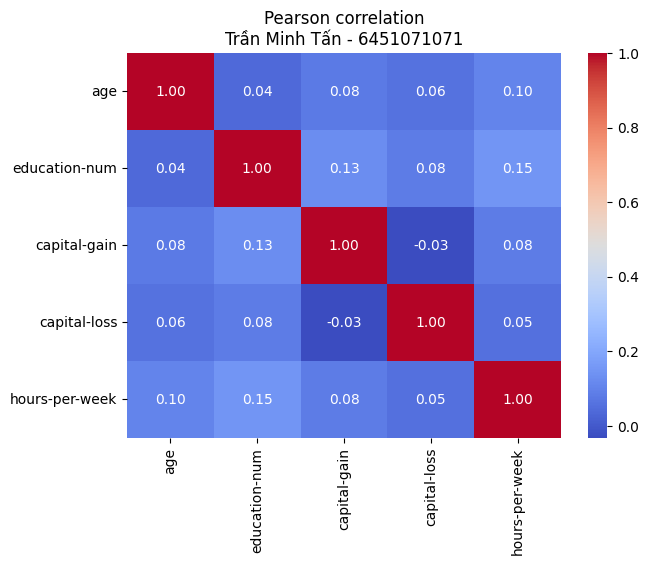

Cột bị loại: Không có cột nào vượt ngưỡng 0.8


In [4]:
info("Câu 3 - Độ tương đồng Pearson")

num_cols = df.select_dtypes(include=np.number).columns
corr = df[num_cols].corr(method="pearson")
print(corr.round(3))

plt.figure(figsize=(7,5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title(f"Pearson correlation\n{HO_TEN} - {MSSV}")
plt.show()

# Loại bỏ cột có độ tương đồng cao
THRESH = 0.8
to_drop = set()
for i in range(len(corr.columns)):
    for j in range(i):
        if abs(corr.iloc[i, j]) > THRESH:
            print(f"Tương quan cao: {corr.columns[i]} - {corr.columns[j]} = {corr.iloc[i,j]:.2f}")
            to_drop.add(corr.columns[i])

print("Cột bị loại:", list(to_drop) if to_drop else "Không có cột nào vượt ngưỡng " + str(THRESH))
df = df.drop(columns=list(to_drop))

## Cell 5: Câu 4 - Tách thuộc tính thường và thuộc tính quyết định

In [5]:
info("Câu 4 - Tách thuộc tính thường và thuộc tính quyết định")

X = df.drop(columns=["income"])   # thuộc tính bình thường (còn cột _set để tách lại ở câu 6)
y = df["income"]                  # thuộc tính quyết định

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
print(y.value_counts())

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 4 - Tách thuộc tính thường và thuộc tính quyết định
Kích thước X: (45222, 14)
Kích thước y: (45222,)
income
<=50K    34014
>50K     11208
Name: count, dtype: int64


## Cell 6: Câu 5 - Chuyển đổi cột không phải dạng số sang one-hot vector

In [6]:
info("Câu 5 - Chuyển đổi cột không phải dạng số sang one-hot vector")

cat_cols = X.select_dtypes(include="object").columns.drop("_set")
print("Các cột dạng chữ:", list(cat_cols))

X_enc = pd.get_dummies(X, columns=cat_cols, dtype=int)
print("Số cột sau one-hot:", X_enc.shape[1])
X_enc.head()

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 5 - Chuyển đổi cột không phải dạng số sang one-hot vector
Các cột dạng chữ: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Số cột sau one-hot: 104


,age,education-num,capital-gain,capital-loss,hours-per-week,_set,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,train,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,13,0,0,13,train,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,38,9,0,0,40,train,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
3,53,7,0,0,40,train,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,40,train,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


## Cell 7: Câu 6 - Tách dữ liệu thành tập huấn luyện và kiểm thử như ban đầu

In [7]:
info("Câu 6 - Tách dữ liệu thành tập huấn luyện và kiểm thử")

is_train = X_enc["_set"] == "train"
X_train = X_enc[is_train].drop(columns="_set")
X_test  = X_enc[~is_train].drop(columns="_set")
y_train = y[is_train]
y_test  = y[~is_train]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 6 - Tách dữ liệu thành tập huấn luyện và kiểm thử
X_train: (30162, 103) | y_train: (30162,)
X_test : (15060, 103) | y_test : (15060,)


## Cell 8: Câu 7 - Cây ID3

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 7 - Cây ID3
Accuracy ID3: 0.8408
              precision    recall  f1-score   support

       <=50K       0.85      0.96      0.90     11360
        >50K       0.78      0.49      0.60      3700

    accuracy                           0.84     15060
   macro avg       0.82      0.72      0.75     15060
weighted avg       0.83      0.84      0.83     15060



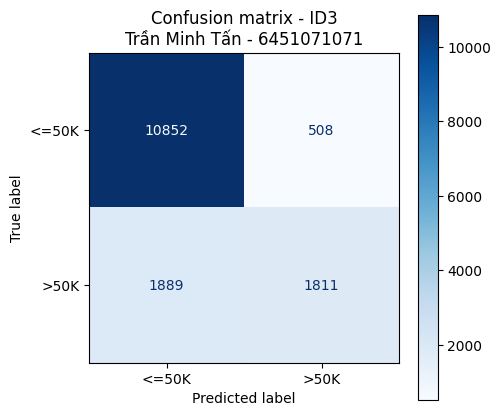

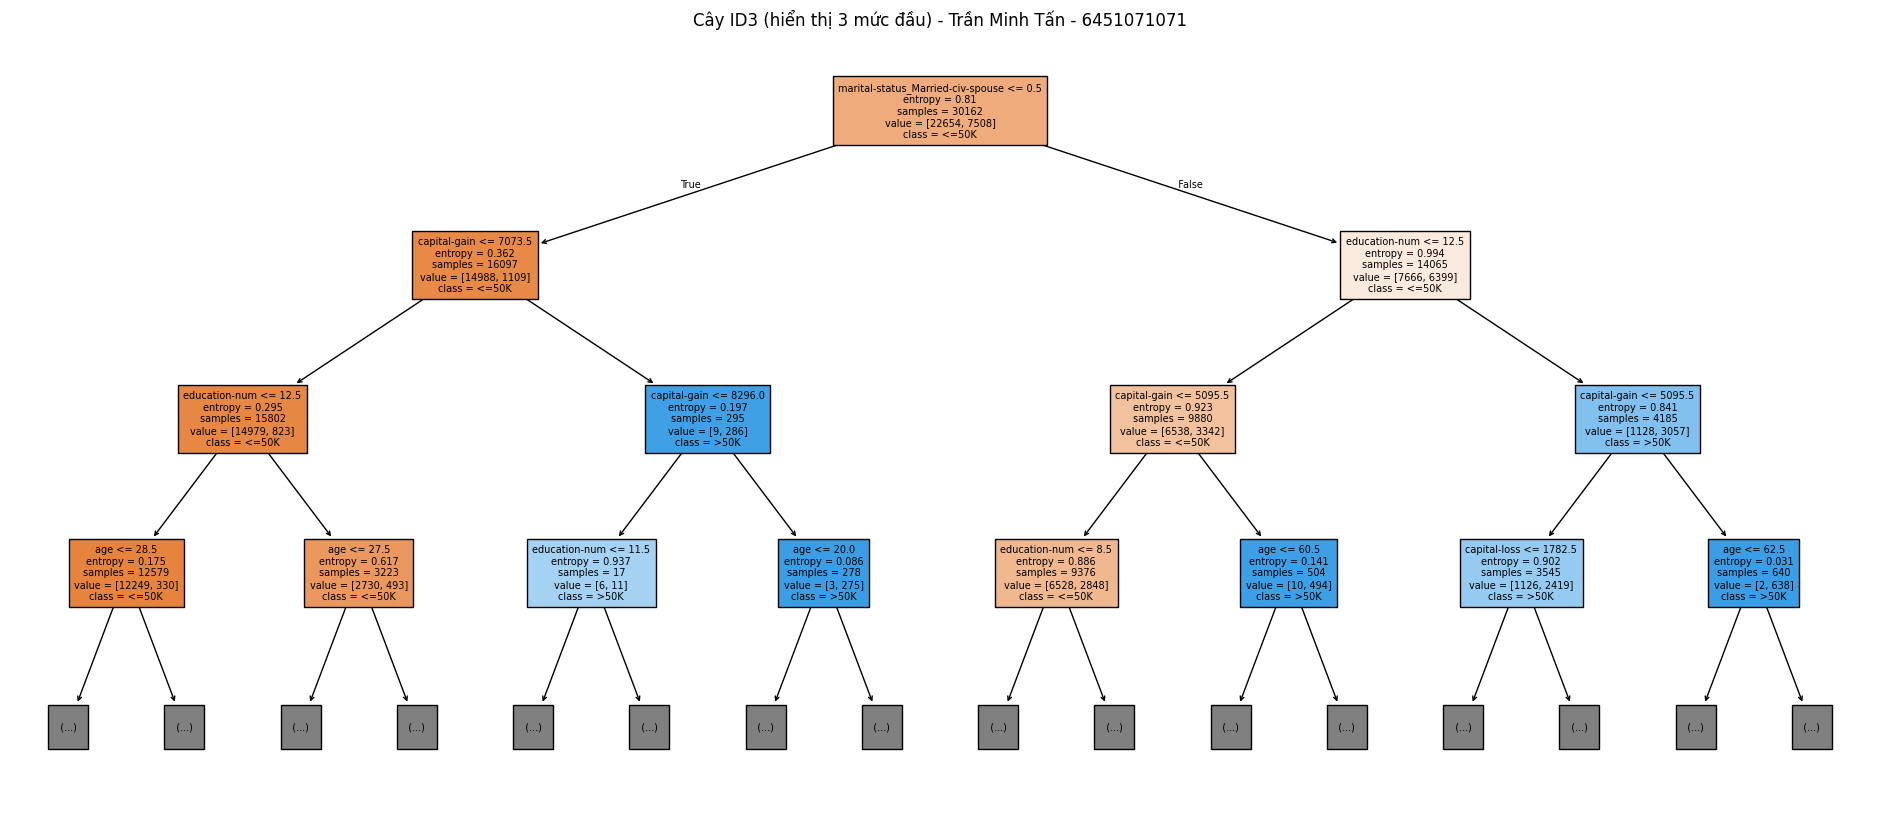

In [8]:
info("Câu 7 - Cây ID3")

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score)

# ID3 dùng entropy (information gain)
id3 = DecisionTreeClassifier(criterion="entropy", max_depth=5, random_state=42)
id3.fit(X_train, y_train)
pred_id3 = id3.predict(X_test)

print("Accuracy ID3:", round(accuracy_score(y_test, pred_id3), 4))
print(classification_report(y_test, pred_id3))

# Ma trận nhầm lẫn
fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_id3, cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix - ID3\n{HO_TEN} - {MSSV}")
plt.show()

# Biểu diễn cây
plt.figure(figsize=(24,10))
plot_tree(id3, feature_names=X_train.columns, class_names=id3.classes_,
          filled=True, fontsize=7, max_depth=3)
plt.title(f"Cây ID3 (hiển thị 3 mức đầu) - {HO_TEN} - {MSSV}")
plt.show()

## Cell 9: Câu 8 - Cây CART

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 8 - Cây CART
Accuracy CART: 0.8407
              precision    recall  f1-score   support

       <=50K       0.85      0.95      0.90     11360
        >50K       0.78      0.49      0.60      3700

    accuracy                           0.84     15060
   macro avg       0.82      0.72      0.75     15060
weighted avg       0.83      0.84      0.83     15060



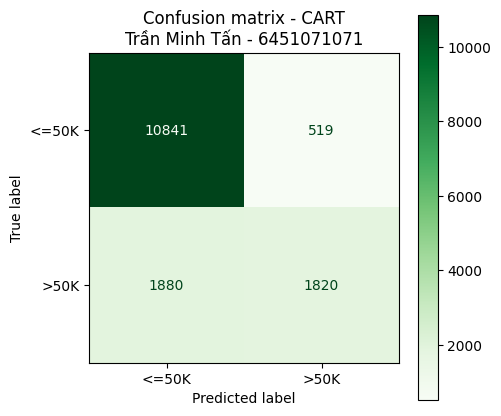

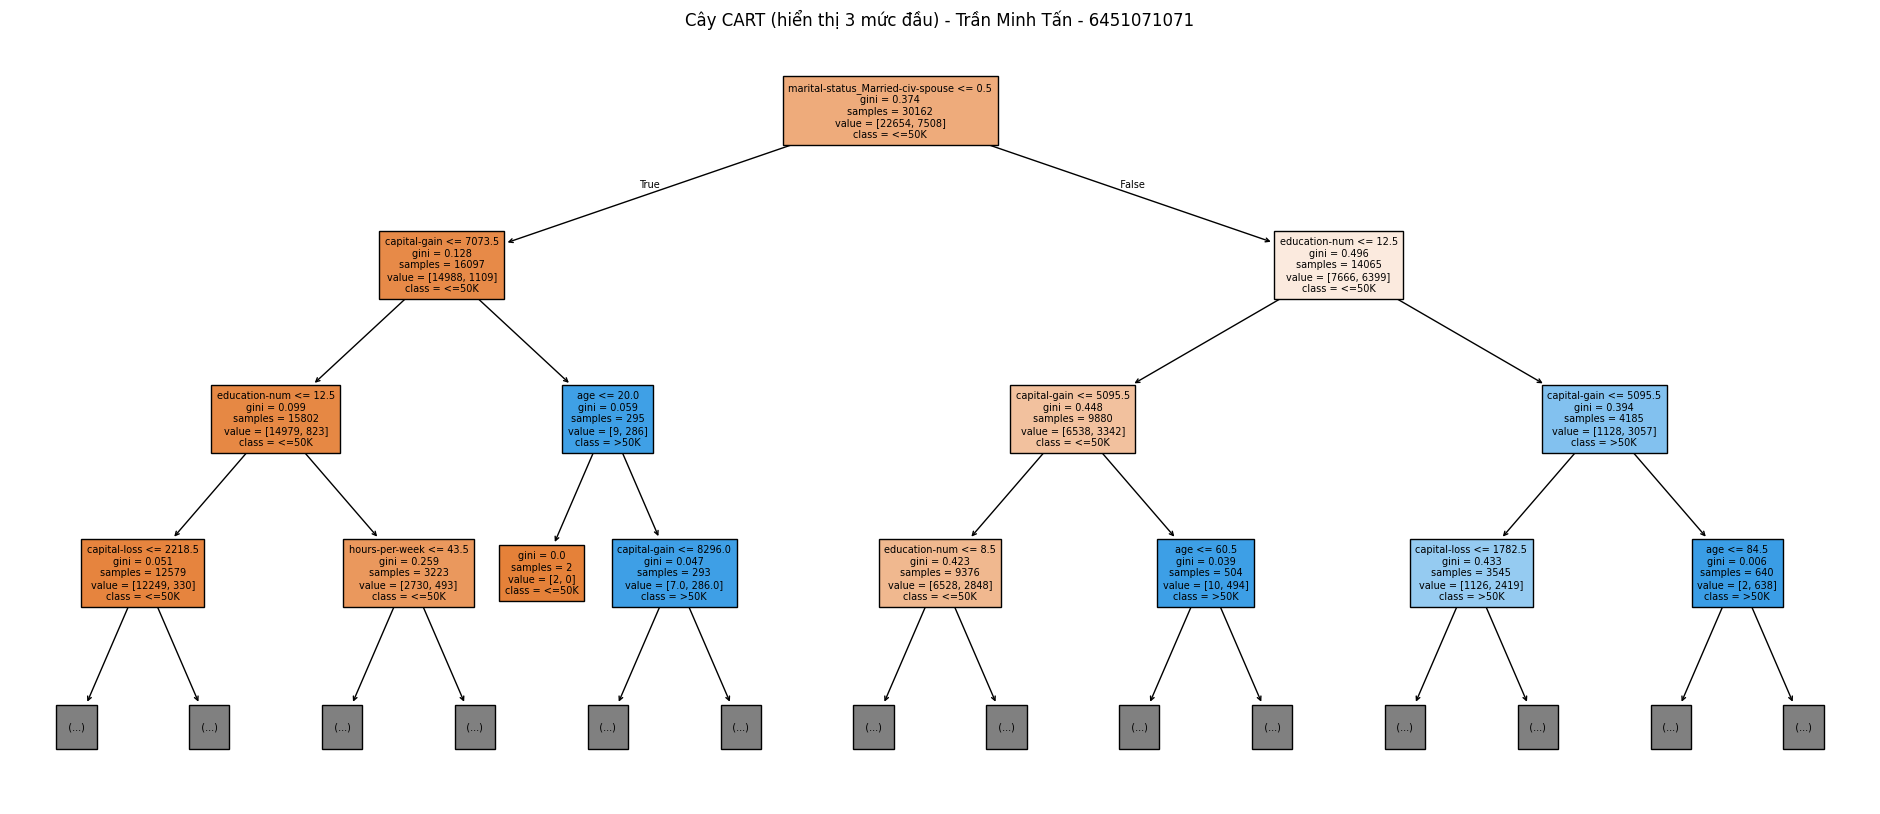

In [9]:
info("Câu 8 - Cây CART")

# CART dùng gini
cart = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42)
cart.fit(X_train, y_train)
pred_cart = cart.predict(X_test)

print("Accuracy CART:", round(accuracy_score(y_test, pred_cart), 4))
print(classification_report(y_test, pred_cart))

fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_cart, cmap="Greens", ax=ax)
ax.set_title(f"Confusion matrix - CART\n{HO_TEN} - {MSSV}")
plt.show()

plt.figure(figsize=(24,10))
plot_tree(cart, feature_names=X_train.columns, class_names=cart.classes_,
          filled=True, fontsize=7, max_depth=3)
plt.title(f"Cây CART (hiển thị 3 mức đầu) - {HO_TEN} - {MSSV}")
plt.show()

## Cell 10: Câu 9 - Naive Bayes

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 9 - Naive Bayes
Accuracy Naive Bayes: 0.8029
              precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



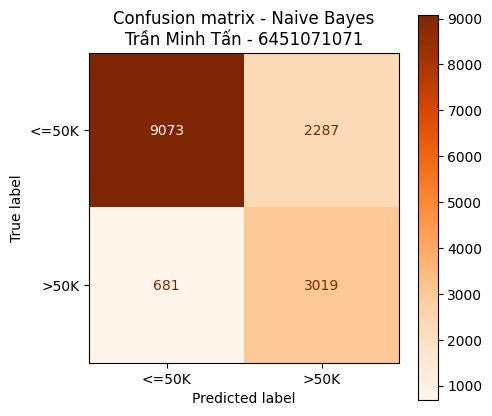

In [10]:
info("Câu 9 - Naive Bayes")

from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)

print("Accuracy Naive Bayes:", round(accuracy_score(y_test, pred_nb), 4))
print(classification_report(y_test, pred_nb))

fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_nb, cmap="Oranges", ax=ax)
ax.set_title(f"Confusion matrix - Naive Bayes\n{HO_TEN} - {MSSV}")
plt.show()

## Cell 11: Câu 10 - So sánh kết quả các mô hình

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Câu 10 - So sánh kết quả các mô hình


,Accuracy,Precision,Recall,F1-score
Mô hình,,,,
ID3,0.8408,0.7809,0.4895,0.6018
CART,0.8407,0.7781,0.4919,0.6027
Naive Bayes,0.8029,0.5690,0.8159,0.6704


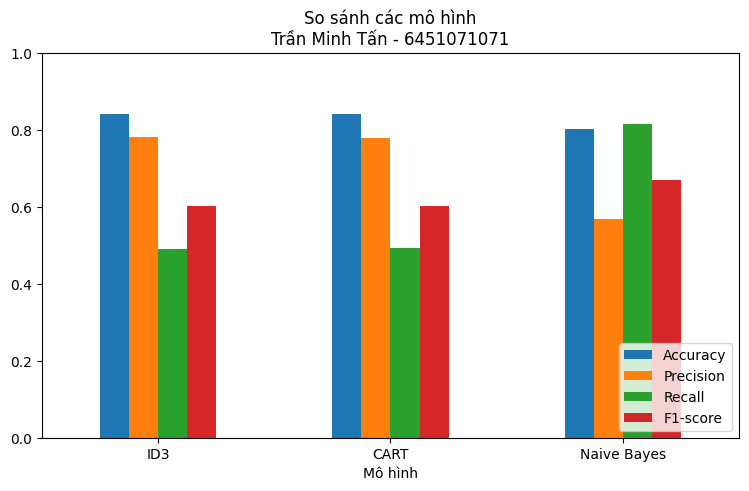

Mô hình có Accuracy cao nhất: ID3 (0.8408)


In [11]:
info("Câu 10 - So sánh kết quả các mô hình")

results = []
for name, pred in [("ID3", pred_id3), ("CART", pred_cart), ("Naive Bayes", pred_nb)]:
    results.append({
        "Mô hình":   name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label=">50K"),
        "Recall":    recall_score(y_test, pred, pos_label=">50K"),
        "F1-score":  f1_score(y_test, pred, pos_label=">50K"),
    })

res = pd.DataFrame(results).set_index("Mô hình").round(4)
display(res)

res.plot(kind="bar", figsize=(9,5), ylim=(0,1))
plt.title(f"So sánh các mô hình\n{HO_TEN} - {MSSV}")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

best = res["Accuracy"].idxmax()
print(f"Mô hình có Accuracy cao nhất: {best} ({res.loc[best,'Accuracy']})")